# Sieci Kohonena - porównanie

In [1]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
import itertools
from collections import Counter
import seaborn as sns

c:\Users\msado\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
def funkcja_wygaszajaca(t, wygaszanie):
    return np.exp(- t / wygaszanie)

def funkcja_Gaussa(d2_grid, sigma):
    return np.exp(-d2_grid / (2 * sigma**2))

def meksykanski_kapelusz(d2_grid, sigma):
    val = -d2_grid / (sigma**2)
    return (1 + val) * np.exp(val / 2)

In [3]:
class Kohonen:
    def __init__(self, M, N, len_wejscia, iteracje, sigma, funkcja_sasiedztwa, wygaszanie):
        self.M = M
        self.N = N
        self.len_wejscia = len_wejscia
        self.iteracje = iteracje
        self.sigma = sigma
        self.wagi = None
        self.funkcja_sasiedztwa = funkcja_sasiedztwa
        self.wygaszanie = wygaszanie
        self.min_vals = 0
        self.max_vals = 1

    def znajdz_najblizszy(self, x):
        # odległość euklidesowa
        odleglosci = np.linalg.norm(self.wagi - x, axis=-1)
        min_idx = np.argmin(odleglosci)
        return np.unravel_index(min_idx, (self.M, self.N))
    
    def update(self, x, best_coord, alpha):
        i_grid, j_grid = np.indices((self.M, self.N))
        d2_grid = (i_grid - best_coord[0])**2 + (j_grid - best_coord[1])**2
        theta = self.funkcja_sasiedztwa(d2_grid, self.sigma)
        theta = theta[..., np.newaxis]
        self.wagi += theta * alpha * (x - self.wagi)
        self.wagi = np.clip(self.wagi, self.min_vals, self.max_vals)

    def train(self, data):
        liczba_probek = data.shape[0]

        self.min_vals = np.min(data, axis=0) 
        self.max_vals = np.max(data, axis=0)
        self.wagi = np.random.uniform(self.min_vals, self.max_vals, (self.M, self.N, self.len_wejscia))

        for t in range(self.iteracje):
            alpha = funkcja_wygaszajaca(t, self.wygaszanie)

            indeksy = np.arange(liczba_probek)
            np.random.shuffle(indeksy)
          
            for idx in indeksy:
                x = data[idx] 
                best_coord = self.znajdz_najblizszy(x)
                self.update(x, best_coord, alpha)

In [4]:
def to_one_hot(y, liczba_klas):
    m = np.zeros((len(y), liczba_klas))
    m[np.arange(len(y)), y.flatten()] = 1
    return m

In [5]:
def train_grid(data, y_etykiety, n, NM_lista, sigma_lista, funkcje, epoki=100, wygaszanie=50):
    df_dane = []

    kombinacje = list(itertools.product(funkcje, sigma_lista, NM_lista))
    calkowita_liczba_modeli = len(kombinacje)
        
    pasek_postepu = tqdm(kombinacje, total=calkowita_liczba_modeli, desc="Trening", unit="model")
    
    for funkcja, sig, nm in pasek_postepu:
                nazwa_funkcji = funkcja.__name__ 
                
                model = Kohonen(nm, nm, n, epoki, sig, funkcja, wygaszanie)
                model.train(data)

                neurony_klasy = {(i, j): [] for i in range(model.M) for j in range(model.N)}
                etykiety_plaskie = y_etykiety.flatten()
                
                for idx, x in enumerate(data):
                    bmu_coord = model.znajdz_najblizszy(x)
                    neurony_klasy[bmu_coord].append(etykiety_plaskie[idx])
                    
                poprawne_trafienia = 0
                wszystkie_probki = len(data)
                
                for i in range(model.M):
                    for j in range(model.N):
                        klasy_w_neuronie = neurony_klasy[(i, j)]
                        if len(klasy_w_neuronie) > 0:
                            dominujaca_klasa, liczba_w_dominujacej = Counter(klasy_w_neuronie).most_common(1)[0]
                            poprawne_trafienia += liczba_w_dominujacej
                            
                acc = poprawne_trafienia / wszystkie_probki
                
                df_dane.append({
                    'Rozmiar': f"{nm}x{nm}",
                    'Sigma': sig,
                    'Funkcja': nazwa_funkcji,
                    'Accuracy (%)': round(acc * 100, 2)
                })
    
    df = pd.DataFrame(df_dane)
    df = df.sort_values(by='Accuracy (%)', ascending=False).reset_index(drop=True)
    return df

In [6]:
def train_N(data, y_etykiety, n, NM_lista, sigma_lista, funkcje, N, epoki=100, wygaszanie=50):
    wszystkie_wyniki = []
        
    for i in range(N):
        df_pojedyncze = train_grid(data, y_etykiety, n, NM_lista, sigma_lista, funkcje, epoki, wygaszanie)
        
        df_pojedyncze['Przebieg'] = i + 1 
        wszystkie_wyniki.append(df_pojedyncze)

    df_pelne = pd.concat(wszystkie_wyniki, ignore_index=True)
    
    df_pelne['Kombinacja'] = df_pelne['Rozmiar'] + " | Sigma=" + df_pelne['Sigma'].astype(str) + " | " + df_pelne['Funkcja']
    
    tabela_statystyk = df_pelne.groupby(['Kombinacja', 'Rozmiar', 'Sigma', 'Funkcja'])['Accuracy (%)'].agg(['mean', 'std']).reset_index()
    
    tabela_statystyk.rename(columns={'mean': 'Średnia Acc (%)', 'std': 'Odchylenie Std'}, inplace=True)
    tabela_statystyk = tabela_statystyk.sort_values(by='Średnia Acc (%)', ascending=False).reset_index(drop=True)
    
    return df_pelne, tabela_statystyk

In [7]:
def boxplot_porownanie_funkcji(df_pelne, N):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

    df = df_pelne.copy()
    df['Rozmiar_num'] = df['Rozmiar'].apply(lambda x: int(x.split('x')[0]))
    df_sorted = df.sort_values(by=['Rozmiar_num', 'Sigma'])
    kolejnosc_rozmiarow = df_sorted['Rozmiar'].unique()
        
    df_gauss = df_sorted[df_sorted['Funkcja'] == 'funkcja_Gaussa']
    
    sns.boxplot(
        data=df_gauss, x='Rozmiar', y='Accuracy (%)', hue='Sigma', 
        ax=axes[0], palette='Set2', order=kolejnosc_rozmiarow
    )
    
    axes[0].set_title('Funkcja Gaussa', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Rozmiar siatki (NxN)', fontsize=12)
    axes[0].set_ylabel('Accuracy (%)', fontsize=12)
    axes[0].grid(axis='y', linestyle='--', alpha=0.7)
    
    axes[0].get_legend().remove()

    df_kapelusz = df_sorted[df_sorted['Funkcja'] == 'meksykanski_kapelusz']
    
    sns.boxplot(
        data=df_kapelusz, x='Rozmiar', y='Accuracy (%)', hue='Sigma', 
        ax=axes[1], palette='Set2', order=kolejnosc_rozmiarow
    )
    
    axes[1].set_title('Meksykański kapelusz', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Rozmiar siatki (NxN)', fontsize=12)
    axes[1].set_ylabel('')
    axes[1].grid(axis='y', linestyle='--', alpha=0.7)
    
    axes[1].legend(title='Wartość sigma', bbox_to_anchor=(1.05, 1), loc='upper left')

    fig.suptitle(f'Zależność Accuracy od rozmiaru i sigmy ({N} powtórzeń)', fontsize=16)
    plt.tight_layout()
    plt.show()

# Dane hexagon

In [8]:
hexagon = pd.read_csv("mio2/hexagon.csv")

hexagon_data = hexagon[['x', 'y']].to_numpy() 
y_etykiety = hexagon[['c']].to_numpy().astype(int) 

liczba_klas = len(np.unique(y_etykiety))
y = to_one_hot(y_etykiety, liczba_klas)
n = hexagon_data.shape[1]

In [9]:
N = 5
NM = [4, 6, 10]
sigma = [0.1, 0.4, 0.7, 1, 2, 4, 6, 8]
funkcje = [funkcja_Gaussa, meksykanski_kapelusz]

In [10]:
hexagon_full, hexagon_full_avg = train_N(hexagon_data, y_etykiety, n, NM, sigma, funkcje, N)

display(hexagon_full_avg)

Trening:   0%|          | 0/48 [00:00<?, ?model/s]

Trening: 100%|██████████| 48/48 [02:14<00:00,  2.80s/model]


,Kombinacja,Rozmiar,Sigma,Funkcja,Średnia Acc (%),Odchylenie Std
0,10x10 | Sigma=2.0 | funkcja_Gaussa,10x10,2.0,funkcja_Gaussa,98.266,0.347462
1,10x10 | Sigma=0.7 | funkcja_Gaussa,10x10,0.7,funkcja_Gaussa,97.966,0.430384
2,10x10 | Sigma=0.4 | funkcja_Gaussa,10x10,0.4,funkcja_Gaussa,97.936,0.252547
3,10x10 | Sigma=8.0 | meksykanski_kapelusz,10x10,8.0,meksykanski_kapelusz,97.934,0.535005
4,10x10 | Sigma=0.1 | funkcja_Gaussa,10x10,0.1,funkcja_Gaussa,97.932,0.093113
5,10x10 | Sigma=1.0 | funkcja_Gaussa,10x10,1.0,funkcja_Gaussa,97.864,0.297120
6,10x10 | Sigma=0.1 | meksykanski_kapelusz,10x10,0.1,meksykanski_kapelusz,97.832,0.116705
7,6x6 | Sigma=2.0 | funkcja_Gaussa,6x6,2.0,funkcja_Gaussa,97.800,0.518556
8,10x10 | Sigma=4.0 | funkcja_Gaussa,10x10,4.0,funkcja_Gaussa,97.666,0.235117
9,10x10 | Sigma=6.0 | meksykanski_kapelusz,10x10,6.0,meksykanski_kapelusz,97.434,0.344572


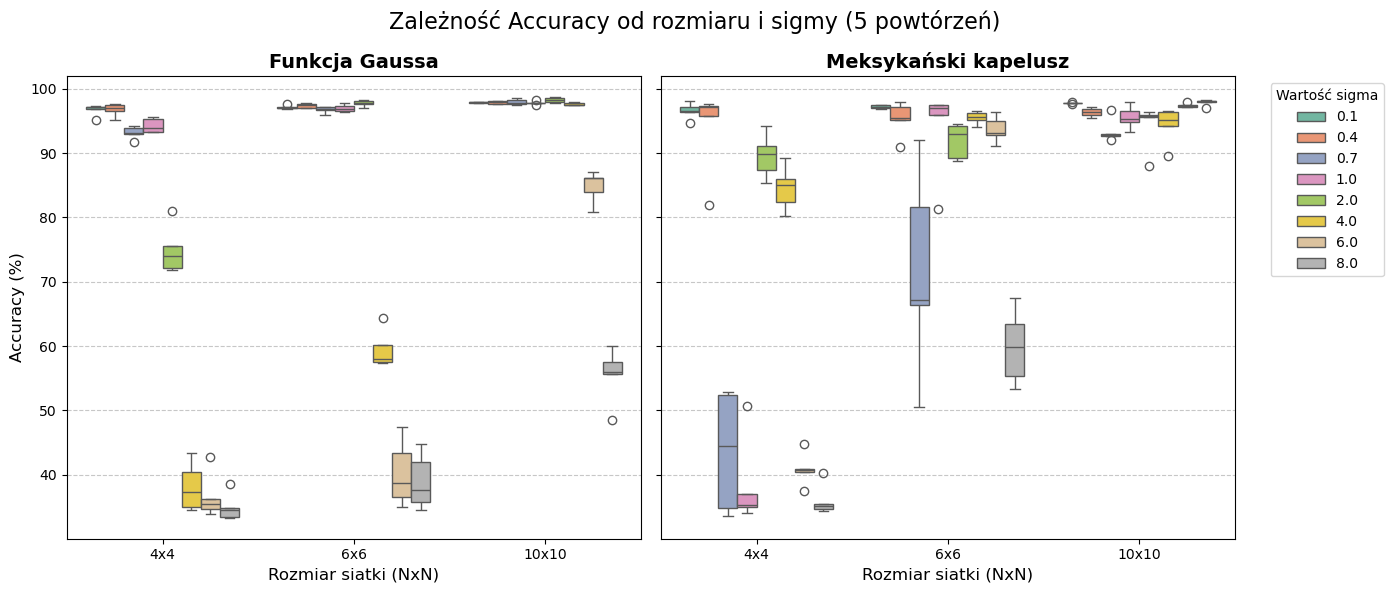

In [11]:
boxplot_porownanie_funkcji(hexagon_full, N)

# Dane cube

In [15]:
cube = pd.read_csv("mio2/cube.csv")

cube_data = cube[['x', 'y', 'z']].to_numpy() 
y_etykiety = cube[['c']].to_numpy().astype(int) 

liczba_klas = len(np.unique(y_etykiety))
y = to_one_hot(y_etykiety, liczba_klas)
n = cube_data.shape[1]

In [16]:
N = 5
NM = [4, 6, 10]
sigma = [0.1, 0.4, 0.7, 1, 2, 4, 6, 8]
funkcje = [funkcja_Gaussa, meksykanski_kapelusz]

In [17]:
cube_full, cube_full_avg = train_N(cube_data, y_etykiety, n, NM, sigma, funkcje, N)

display(cube_full_avg)

Trening: 100%|██████████| 48/48 [04:37<00:00,  5.78s/model]


,Kombinacja,Rozmiar,Sigma,Funkcja,Średnia Acc (%),Odchylenie Std
0,6x6 | Sigma=0.4 | meksykanski_kapelusz,6x6,0.4,meksykanski_kapelusz,95.098,0.640601
1,10x10 | Sigma=1.0 | funkcja_Gaussa,10x10,1.0,funkcja_Gaussa,95.052,0.448798
2,10x10 | Sigma=2.0 | funkcja_Gaussa,10x10,2.0,funkcja_Gaussa,94.684,0.541969
3,10x10 | Sigma=0.4 | funkcja_Gaussa,10x10,0.4,funkcja_Gaussa,94.664,0.523479
4,10x10 | Sigma=0.7 | funkcja_Gaussa,10x10,0.7,funkcja_Gaussa,94.630,0.622495
5,10x10 | Sigma=0.7 | meksykanski_kapelusz,10x10,0.7,meksykanski_kapelusz,94.616,0.877770
6,4x4 | Sigma=0.1 | funkcja_Gaussa,4x4,0.1,funkcja_Gaussa,94.500,0.477127
7,10x10 | Sigma=0.1 | meksykanski_kapelusz,10x10,0.1,meksykanski_kapelusz,94.418,0.257138
8,10x10 | Sigma=0.1 | funkcja_Gaussa,10x10,0.1,funkcja_Gaussa,94.316,0.280589
9,4x4 | Sigma=0.1 | meksykanski_kapelusz,4x4,0.1,meksykanski_kapelusz,94.200,0.410792


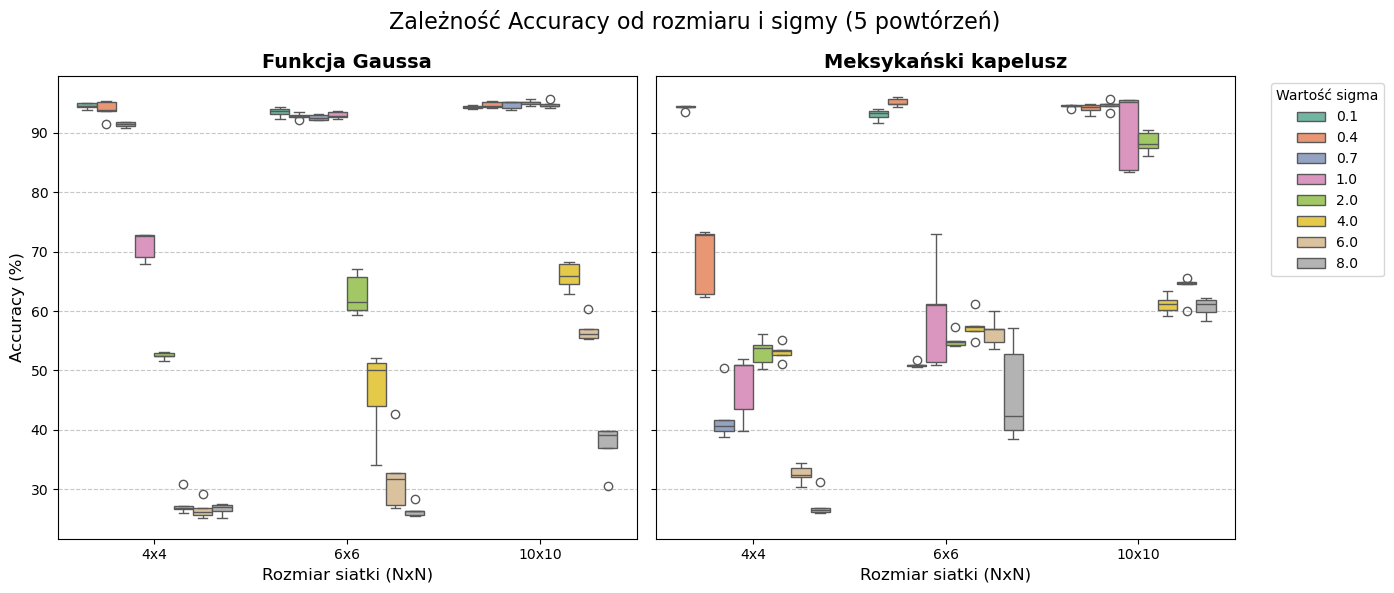

In [18]:
boxplot_porownanie_funkcji(cube_full, N)